# Topological & Structural Analysis of the Indian Stock Market
**ECS414/614 Network Science Theory and Applications, 2026-27-I Term, Assignment**

## Contents
1. Introduction / Problem Statement
2. Methodology (data, preprocessing, edge definition)
3. Data collection and preprocessing
4. Network construction
5. Analysis A: Degree distribution
6. Analysis B: Centrality leaderboard
7. Analysis C: Clustering coefficient and sector homophily
8. Analysis D: Threshold sensitivity
9. Discussion and Conclusion
10. References

---
## 1. Introduction / Problem Statement
Stock prices do not move independently: common macro shocks, sector dynamics and investor behaviour make many stocks move together. A *correlation network* turns this into a graph: each stock is a **node**, and two stocks are joined by an **edge** when their daily returns are strongly correlated.

In this assignment we build such a network for the **Nifty 500** constituents listed on the National Stock Exchange (NSE) and ask:

* Is the degree distribution random-like (exponential tail) or heavy-tailed / scale-free, with a few massive hubs? (A)
* Which stocks are the hubs, bridges and "well-connected-to-well-connected" nodes? Do they match the index heavyweights? (B)
* Do correlated stocks form triangles, and do those triangles sit inside the same industry sector? (C)
* How fragile is the network structure to our definition of a "connection" (the correlation threshold)? (D)

## 2. Methodology
**Data.** Daily *adjusted* close prices (1 year) of the Nifty 500 constituents, downloaded with `yfinance` (ticker = NSE symbol + `.NS`) and **cached locally** to avoid repeated server requests.

**Preprocessing.** Daily logarithmic returns
$$R_i(t)=\ln\!\left(\frac{P_i(t)}{P_i(t-1)}\right)$$
Stocks with more than 10% missing returns (e.g. halted or recently listed) are dropped so that the correlation matrix is reliable.

**Edge definition.** Pearson correlation $\rho_{ij}$ between return series. For the unweighted network, an edge $i$–$j$ exists if $\rho_{ij} > r$ (threshold $r$). Self-loops are removed. We use only *positive* correlation above the threshold, as specified in the assignment; strongly negative correlations are not treated as connections (we check how rare they are below).

In [ ]:
!pip install -q yfinance pandas numpy networkx matplotlib seaborn scipy

In [ ]:
import os, io, urllib.request, warnings
import yfinance as yf
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')   # clean visual style for all plots

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

## 3. Data collection and preprocessing
### 3.1 Download constituents and prices
The constituent list (including the **Industry** column, used later for sector analysis) and the prices are saved to CSV files. If the files already exist they are re-used, so the NSE and Yahoo servers are not hit again on re-runs. Delete the CSVs to force a fresh download.

In [ ]:
NIFTY500_URL      = "https://nsearchives.nseindia.com/content/indices/ind_nifty500list.csv"
CONSTITUENTS_FILE = 'nifty500_constituents.csv'
PRICES_FILE       = 'nse_historical_prices.csv'
PERIOD            = "1y"

# --- 1. Constituent list (Symbol + Industry) -------------------------------------------
def load_constituents():
    if os.path.exists(CONSTITUENTS_FILE):
        print(f"Loading constituents from local file '{CONSTITUENTS_FILE}'.")
        return pd.read_csv(CONSTITUENTS_FILE)
    try:
        req = urllib.request.Request(
            NIFTY500_URL,
            headers={'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 '
                                   '(KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36'})
        with urllib.request.urlopen(req) as response:
            csv_data = response.read().decode('utf-8')
        df = pd.read_csv(io.StringIO(csv_data))
        df.to_csv(CONSTITUENTS_FILE, index=False)
        print(f"Successfully loaded {len(df)} symbols from Nifty 500.")
        return df
    except Exception as e:
        print(f"Failed to fetch online list: {e}. Using an expanded fallback sample.")
        fallback = {
            'RELIANCE': 'Oil Gas & Consumable Fuels', 'TCS': 'Information Technology',
            'HDFCBANK': 'Financial Services', 'INFY': 'Information Technology',
            'ICICIBANK': 'Financial Services', 'HINDUNILVR': 'Fast Moving Consumer Goods',
            'SBIN': 'Financial Services', 'BHARTIARTL': 'Telecommunication',
            'ITC': 'Fast Moving Consumer Goods', 'KOTAKBANK': 'Financial Services',
            'LT': 'Construction', 'AXISBANK': 'Financial Services',
            'ASIANPAINT': 'Consumer Durables', 'MARUTI': 'Automobile and Auto Components',
            'HCLTECH': 'Information Technology', 'SUNPHARMA': 'Healthcare',
            'TITAN': 'Consumer Durables', 'ULTRACEMCO': 'Construction Materials',
            'WIPRO': 'Information Technology', 'BAJFINANCE': 'Financial Services'}
        return pd.DataFrame({'Symbol': list(fallback), 'Industry': list(fallback.values())})

constituents = load_constituents()
symbols = constituents['Symbol'].tolist()
tickers = [s + '.NS' for s in symbols]          # '.NS' = National Stock Exchange suffix

# --- 2. Historical adjusted close prices -------------------------------------------------
if os.path.exists(PRICES_FILE):
    print(f"Loading prices from local file '{PRICES_FILE}' (no download needed).")
else:
    print(f"Downloading data for {len(tickers)} stocks...")
    raw = yf.download(tickers, period=PERIOD, progress=False, auto_adjust=True)
    # Handle yfinance multi-index columns reliably
    if isinstance(raw.columns, pd.MultiIndex):
        prices = raw['Close'] if 'Close' in raw.columns.levels[0] else raw.xs('Close', axis=1, level=0, drop_level=True)
    else:
        prices = raw
    prices.to_csv(PRICES_FILE)                  # save locally to prevent redundant requests
    print(f"Data saved locally to '{PRICES_FILE}'.")

# --- 3. Confirm both CSV files are stored in this runtime's working folder (/content in Colab) ---
print("\nWorking folder:", os.getcwd())
for f in (CONSTITUENTS_FILE, PRICES_FILE):
    if os.path.exists(f):
        print(f"  [saved] {os.path.abspath(f)}  ({os.path.getsize(f)/1024:,.0f} KB)")
    else:
        print(f"  [missing] {f}  (the online list could not be fetched; the fallback sample is in use)")


Loading constituents from local file 'nifty500_constituents.csv'.
Loading prices from local file 'nse_historical_prices.csv' (no download needed).

Working folder: /content
  [saved] /content/nifty500_constituents.csv  (32 KB)
  [saved] /content/nse_historical_prices.csv  (1,997 KB)


### 3.1b Export: constituent list + Close prices in one CSV
The constituent file has no prices, and the price file has no company names or industries. This step joins them into **one CSV**: one row per Nifty 500 stock (Company Name, Industry, Symbol, Series, ISIN, Ticker), then `Latest_Close` / `Latest_Date`, then one column of adjusted Close price for every trading day. Tickers that Yahoo returned nothing for are kept with empty prices so no constituent is lost. The file is saved in the Colab working folder (`/content`, shown in the Files panel on the left); nothing is downloaded to your computer.

# Note: The Two Price files

The merged file's prices are copied straight from `nse_historical_prices.csv`, with no recalculation or rounding. Only the layout differs.

| | `nse_historical_prices.csv` | `nifty500_with_close_prices.csv` |
|---|---|---|
| **Rows** | one per date | one per stock |
| **Columns** | one per stock (e.g. `RELIANCE.NS`) | one per date, after the company details |
| **Prices** | adjusted Close | the same adjusted Close |

* `nse_historical_prices.csv` is the file used to calculate the log returns $R_i(t)$.
* `nifty500_with_close_prices.csv` is an extra copy for reading. It also has `Latest_Close` and `Latest_Date` columns, which are the last value from the same data.

In [ ]:
# --- Merge constituents + Close prices into ONE csv and download it ---------------------
MERGED_FILE = 'nifty500_with_close_prices.csv'

px = pd.read_csv(PRICES_FILE, index_col=0, parse_dates=True)       # rows = dates, columns = tickers
px = px.sort_index()

# wide table: one row per ticker, one column per trading day (YYYY-MM-DD)
px_wide = px.T.copy()
px_wide.columns = [d.strftime('%Y-%m-%d') for d in px_wide.columns]

# last available Close for each stock (NaN-safe)
last_valid = px.apply(lambda s: s.last_valid_index())
latest = pd.DataFrame({'Latest_Close': px.apply(lambda s: s.dropna().iloc[-1] if s.notna().any() else np.nan),
                       'Latest_Date' : last_valid.dt.strftime('%Y-%m-%d')})

merged = constituents.copy()
merged['Ticker'] = merged['Symbol'] + '.NS'
merged = (merged.merge(latest,   left_on='Ticker', right_index=True, how='left')
                .merge(px_wide, left_on='Ticker', right_index=True, how='left'))

merged.to_csv(MERGED_FILE, index=False)
n_with_price = int(merged['Latest_Close'].notna().sum())
print(f"Saved '{MERGED_FILE}': {merged.shape[0]} stocks x {merged.shape[1]} columns "
      f"({n_with_price} with prices, {merged.shape[0] - n_with_price} without).")
print(f"Price columns: {px_wide.shape[1]} trading days, {px_wide.columns[0]} to {px_wide.columns[-1]}")
display(merged.iloc[:5, :9])

print(f"Saved in the Colab working folder: {os.path.abspath(MERGED_FILE)}")


Saved 'nifty500_with_close_prices.csv': 501 stocks x 256 columns (499 with prices, 2 without).
Price columns: 248 trading days, 2025-11-18 to 2026-11-18


,Company Name,Industry,Symbol,Series,ISIN Code,Ticker,Latest_Close,Latest_Date,2025-11-18
0,360 ONE WAM Ltd.,Financial Services,360ONE,EQ,INE466L01038,360ONE.NS,1211.050049,2026-11-18,1064.100830
1,ABB India Ltd.,Capital Goods,ABB,EQ,INE117A01022,ABB.NS,6851.000000,2026-11-18,5000.932617
2,ACC Ltd.,Construction Materials,ACC,EQ,INE012A01025,ACC.NS,1229.800049,2026-11-18,1828.122192
3,ACME Solar Holdings Ltd.,Power,ACMESOLAR,EQ,INE622W01025,ACMESOLAR.NS,409.700012,2026-11-18,246.382843
4,AIA Engineering Ltd.,Capital Goods,AIAENG,EQ,INE212H01026,AIAENG.NS,3327.199951,2026-11-18,3697.700195


Saved in the Colab working folder: /content/nifty500_with_close_prices.csv


### 3.2 Logarithmic returns and cleaning

In [ ]:
# Load the saved data (a fresh start that only depends on the local CSV)
prices_df = pd.read_csv(PRICES_FILE, index_col=0, parse_dates=True)

# Tickers for which Yahoo returned nothing (delisted / dummy symbols) are all-NaN columns
failed = [t for t in tickers if (t not in prices_df.columns) or prices_df[t].isna().all()]
print(f"{len(failed)} tickers returned no price data and are excluded: {failed}")
prices_df = prices_df.dropna(axis=1, how='all')

# Daily logarithmic returns: R_i(t) = ln(P_i(t) / P_i(t-1))
log_returns = np.log(prices_df / prices_df.shift(1)).replace([np.inf, -np.inf], np.nan)
log_returns = log_returns.dropna(how='all')           # drop first row (NaN after shift)

# Drop stocks with too many missing values (e.g. halted trading / recent IPOs)
n_before = log_returns.shape[1]
min_periods = int(len(log_returns) * 0.9)             # require at least 90% of data
log_returns = log_returns.dropna(axis=1, thresh=min_periods)

print(f"Dropped {n_before - log_returns.shape[1]} stocks with >10% missing returns.")
print(f"Returns calculated for {log_returns.shape[1]} stocks over {log_returns.shape[0]} days "
      f"({log_returns.index.min().date()} to {log_returns.index.max().date()}).")

2 tickers returned no price data and are excluded: ['BAGMANE.NS', 'DUMMYHEG.NS']
Dropped 8 stocks with >10% missing returns.
Returns calculated for 491 stocks over 247 days (2025-11-19 to 2026-11-18).


## 4. Network construction
We compute the Pearson correlation matrix of the log-returns and keep an unweighted edge between two stocks when $\rho_{ij} > r$.

**Choice of $r = 0.5$.** This is a common "moderate-to-strong" correlation level in stock-network studies [1]. It is sparse enough that edges carry information (a very low threshold connects almost every pair because all stocks share a common market factor), yet dense enough to keep a rich structure. Section 8 studies how the results change with $r$.

In [ ]:
THRESHOLD = 0.5

# --- 1. Pearson correlation matrix -----------------------------------------------------
corr_matrix = log_returns.corr(method='pearson')

off_diag = corr_matrix.values[np.triu_indices_from(corr_matrix.values, k=1)]
print(f"Pairs: {len(off_diag):,} | mean corr = {np.nanmean(off_diag):.3f} | median = {np.nanmedian(off_diag):.3f}")
print(f"Share of pairs with rho > {THRESHOLD}: {np.nanmean(off_diag > THRESHOLD):.2%}")
print(f"Share of pairs with rho < -{THRESHOLD} (ignored by the positive-threshold rule): {np.nanmean(off_diag < -THRESHOLD):.4%}")

# --- 2. Threshold -> adjacency matrix -> graph -----------------------------------------
def build_graph(corr, r):
    """Unweighted graph: edge if correlation > r (no self-loops)."""
    adj = (corr.values > r).astype(int)
    np.fill_diagonal(adj, 0)
    return nx.from_pandas_adjacency(pd.DataFrame(adj, index=corr.index, columns=corr.columns))

G = build_graph(corr_matrix, THRESHOLD)
print(f"\nGraph built: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges at threshold r={THRESHOLD}.")

# Isolated stocks (no neighbour above the threshold) matter for the later statistics
isolates = list(nx.isolates(G))
G_core = G.subgraph([n for n in G if G.degree(n) > 0]).copy()     # graph without isolated nodes
print(f"Isolated nodes: {len(isolates)} ({len(isolates)/G.number_of_nodes():.1%}); "
      f"non-isolated core: {G_core.number_of_nodes()} nodes.")
comps = sorted(nx.connected_components(G), key=len, reverse=True)
print(f"Connected components: {len(comps)} | giant component: {len(comps[0])} nodes "
      f"({len(comps[0])/G.number_of_nodes():.1%} of all nodes)")

# --- 3. Sector (Industry) label for every node, from the NSE constituent file ----------
if 'Industry' in constituents.columns:
    sector_map = {s + '.NS': ind for s, ind in zip(constituents['Symbol'], constituents['Industry'])}
else:
    sector_map = {}
sector_map = {n: sector_map.get(n, 'Unknown') for n in G.nodes()}
nx.set_node_attributes(G, sector_map, 'sector')
print(f"Number of distinct sectors among nodes: {len(set(sector_map.values()))}")

Pairs: 120,295 | mean corr = 0.242 | median = 0.238
Share of pairs with rho > 0.5: 1.90%
Share of pairs with rho < -0.5 (ignored by the positive-threshold rule): 0.0000%

Graph built: 491 nodes, 2291 edges at threshold r=0.5.
Isolated nodes: 212 (43.2%); non-isolated core: 279 nodes.
Connected components: 226 | giant component: 238 nodes (48.5% of all nodes)
Number of distinct sectors among nodes: 20


### 4.1 Network overview
Node size is proportional to degree, the 10 highest-degree stocks (hubs) are labelled. Isolated nodes are left out of the picture (but not of the analysis).

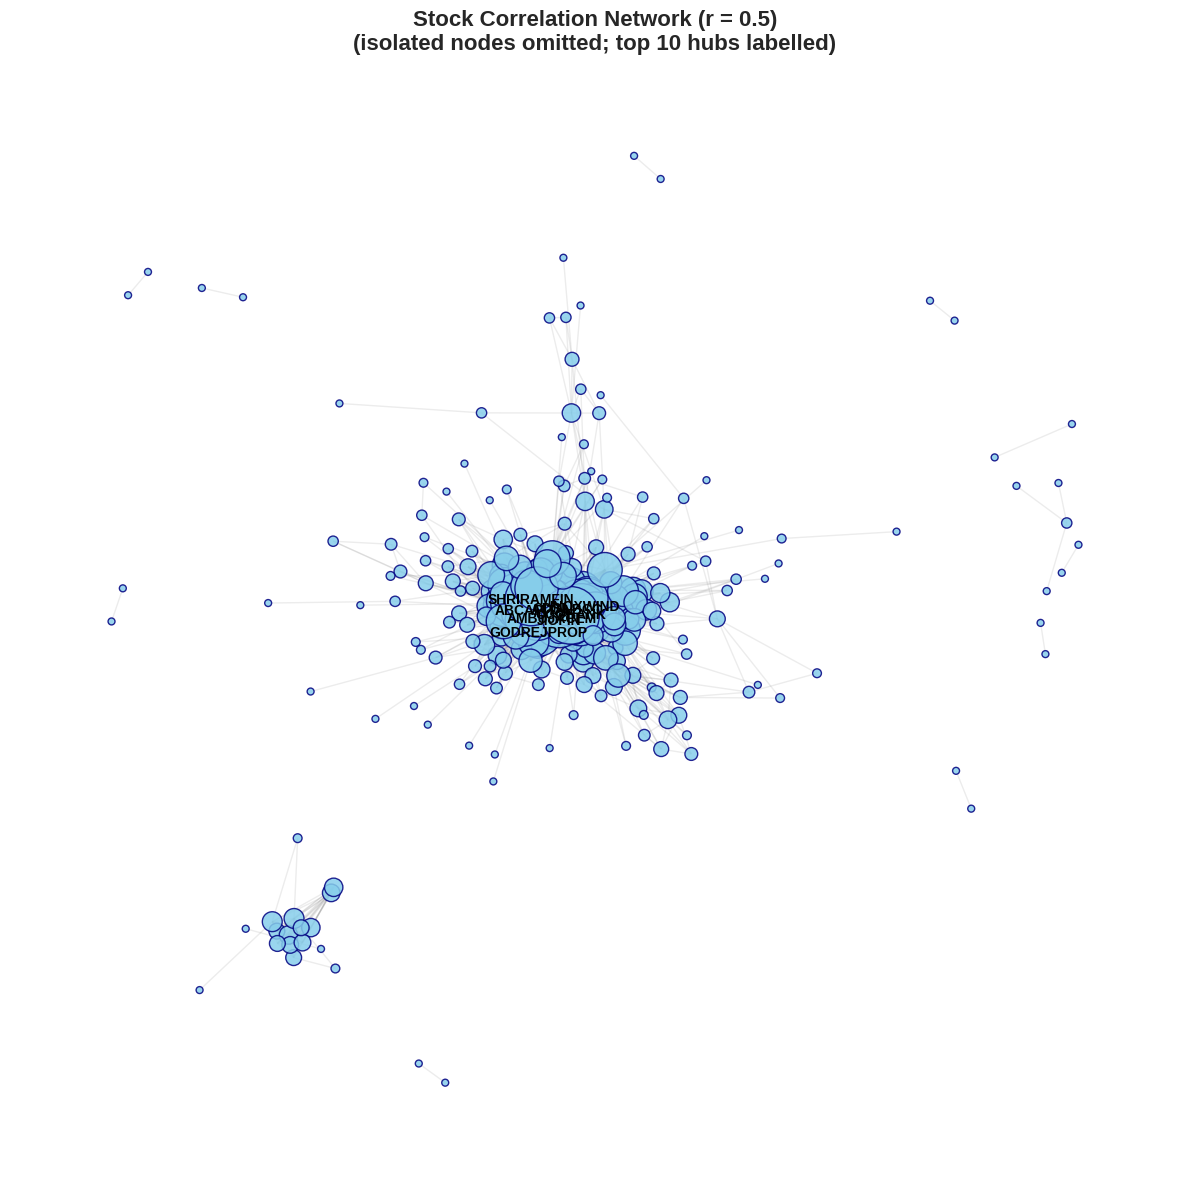

In [ ]:
plt.figure(figsize=(12, 12))

# Spring layout; k controls optimal node distance (larger k spreads nodes out)
pos = nx.spring_layout(G_core, k=0.15, seed=RANDOM_SEED)

degrees_dict = dict(G_core.degree())
node_sizes = [v * 15 + 10 for v in degrees_dict.values()]

nx.draw_networkx_nodes(G_core, pos, node_size=node_sizes, node_color='skyblue',
                       alpha=0.85, edgecolors='navy')
nx.draw_networkx_edges(G_core, pos, alpha=0.15, edge_color='gray')   # low opacity to limit clutter

# Label only the top-10 hubs to avoid overlapping text
top_hubs = sorted(degrees_dict.items(), key=lambda x: x[1], reverse=True)[:10]
nx.draw_networkx_labels(G_core, pos, labels={n: n.replace('.NS', '') for n, _ in top_hubs},
                        font_size=10, font_weight='bold', font_color='black')

plt.title(f'Stock Correlation Network (r = {THRESHOLD})\n(isolated nodes omitted; top 10 hubs labelled)',
          fontsize=16, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()

## 5. Analysis A: Degree distribution
We compute the degree of each node, then plot its frequency distribution on **linear** and **log-log** scales. To judge "random-like vs scale-free" objectively we add:

* a **random-graph baseline**: an Erdős–Rényi graph with the same number of nodes and edges (Poisson degrees, exponentially thin tail);
* the **complementary CDF** $P(K\ge k)$ with two competing fits on the tail: a power law (straight line on log-log axes) vs an exponential (straight line on semi-log axes). The better $R^2$ indicates the better description.

Mean degree = 9.33 | median = 1 | max = 114 (12.2x the mean) | std = 17.71
Random graph baseline (same n, m): max degree = 22, std = 2.94


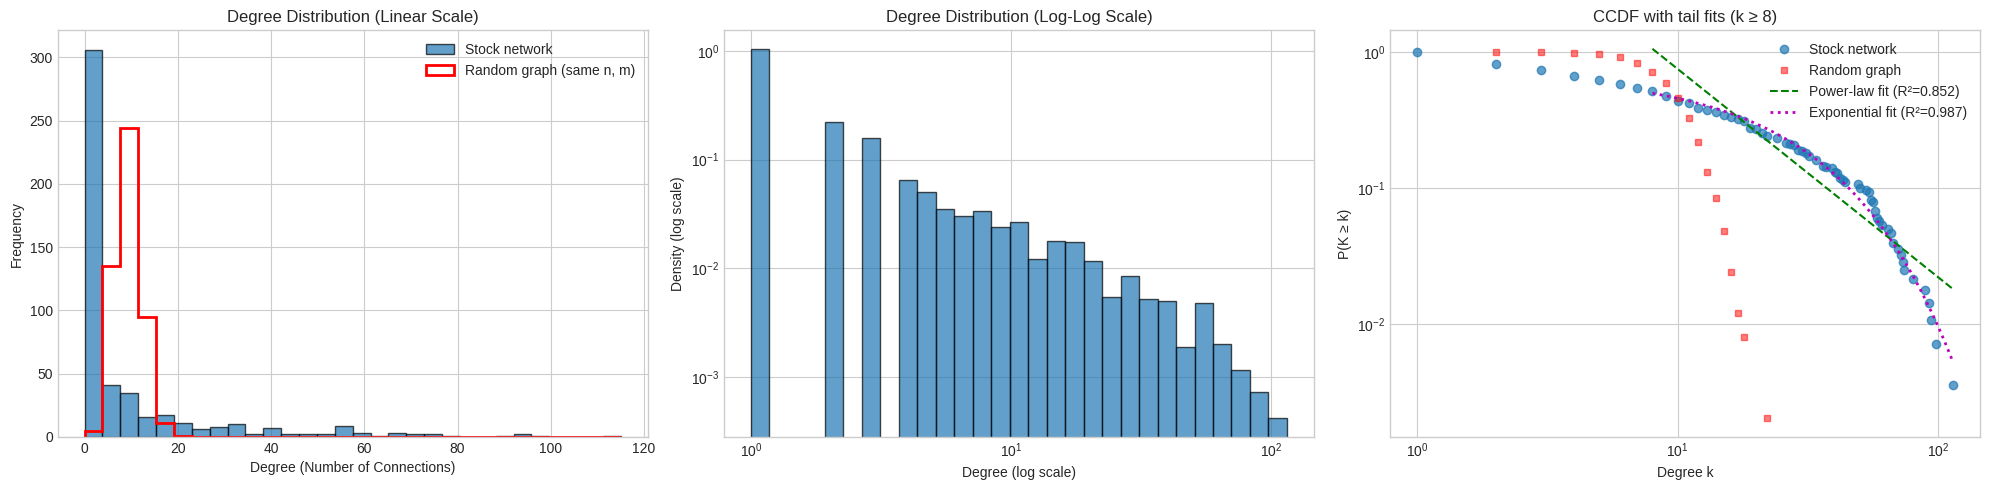

Tail (k >= 8, 144 nodes): power-law R² = 0.852 (CCDF slope -1.53 -> exponent ≈ 2.53), exponential R² = 0.987, MLE exponent ≈ 1.91
Better tail description on this criterion: exponential.
Caveat: R² on log-log CCDFs is only a rough guide; a rigorous test would use Clauset-Shalizi-Newman.


In [ ]:
degrees = np.array([d for _, d in G.degree()])
pos_deg = degrees[degrees > 0]          # log(0) is undefined, so log-log uses only degree > 0

print(f"Mean degree = {degrees.mean():.2f} | median = {np.median(degrees):.0f} | "
      f"max = {degrees.max()} ({degrees.max()/degrees.mean():.1f}x the mean) | std = {degrees.std():.2f}")

# Random (Erdos-Renyi) baseline with the same n and m
G_er = nx.gnm_random_graph(G.number_of_nodes(), G.number_of_edges(), seed=RANDOM_SEED)
er_deg = np.array([d for _, d in G_er.degree()])
print(f"Random graph baseline (same n, m): max degree = {er_deg.max()}, std = {er_deg.std():.2f}")

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# --- Linear scale (identical bins for both so the comparison is fair) ---
lin_bins = np.linspace(0, max(degrees.max(), er_deg.max()) + 1, 31)
axes[0].hist(degrees, bins=lin_bins, edgecolor='black', alpha=0.7, label='Stock network')
axes[0].hist(er_deg, bins=lin_bins, histtype='step', color='red', linewidth=2, label='Random graph (same n, m)')
axes[0].set_title('Degree Distribution (Linear Scale)')
axes[0].set_xlabel('Degree (Number of Connections)'); axes[0].set_ylabel('Frequency'); axes[0].legend()

# --- Log-log scale (log-spaced bins) ---
bins = np.logspace(0, np.log10(pos_deg.max() + 1), 30)
axes[1].hist(pos_deg, bins=bins, density=True, alpha=0.7, edgecolor='black')
axes[1].set_xscale('log'); axes[1].set_yscale('log')
axes[1].set_title('Degree Distribution (Log-Log Scale)')
axes[1].set_xlabel('Degree (log scale)'); axes[1].set_ylabel('Density (log scale)')

# --- CCDF and tail fits ---
def ccdf(x):
    vals = np.sort(np.unique(x))
    return vals, np.array([(x >= v).mean() for v in vals])

k_vals, p_vals = ccdf(pos_deg)
k_er, p_er = ccdf(er_deg[er_deg > 0])
axes[2].loglog(k_vals, p_vals, 'o', label='Stock network', alpha=0.7)
axes[2].loglog(k_er, p_er, 's', color='red', alpha=0.5, markersize=4, label='Random graph')

kmin = max(int(np.median(pos_deg)), 2)          # fit the tail only (k >= median degree)
mask = (k_vals >= kmin) & (p_vals > 0)
if mask.sum() >= 4:
    pl = stats.linregress(np.log10(k_vals[mask]), np.log10(p_vals[mask]))      # power law: log p vs log k
    ex = stats.linregress(k_vals[mask], np.log10(p_vals[mask]))                # exponential: log p vs k
    kk = np.linspace(k_vals[mask].min(), k_vals[mask].max(), 100)
    axes[2].loglog(kk, 10 ** (pl.intercept + pl.slope * np.log10(kk)), 'g--', label=f'Power-law fit (R²={pl.rvalue**2:.3f})')
    axes[2].loglog(kk, 10 ** (ex.intercept + ex.slope * kk), 'm:', linewidth=2, label=f'Exponential fit (R²={ex.rvalue**2:.3f})')
axes[2].set_title(f'CCDF with tail fits (k ≥ {kmin})')
axes[2].set_xlabel('Degree k'); axes[2].set_ylabel('P(K ≥ k)'); axes[2].legend()
plt.tight_layout(); plt.show()

# --- Quantitative summary ---
if mask.sum() >= 4:
    sub = pos_deg[pos_deg >= kmin]
    alpha_mle = 1 + len(sub) / np.sum(np.log(sub / (kmin - 0.5)))   # approx. discrete MLE exponent
    print(f"Tail (k >= {kmin}, {len(sub)} nodes): power-law R² = {pl.rvalue**2:.3f} "
          f"(CCDF slope {pl.slope:.2f} -> exponent ≈ {1 - pl.slope:.2f}), "
          f"exponential R² = {ex.rvalue**2:.3f}, MLE exponent ≈ {alpha_mle:.2f}")
    better = 'power law' if pl.rvalue**2 > ex.rvalue**2 else 'exponential'
    print(f"Better tail description on this criterion: {better}.")
    print("Caveat: R² on log-log CCDFs is only a rough guide; a rigorous test would use Clauset-Shalizi-Newman.")

### Interpretation of the degree distribution
* **Hubs exist.** The mean degree is only about 9 (2 × 2283 edges / 490 nodes at $r=0.5$), but the most connected stock (UCO Bank) has a degree of about 114, i.e. more than ten times the mean. In a random graph with the same density the maximum degree stays close to the mean (see the printed baseline and the red curve): the observed network has a far heavier right tail.
* **Not a clean scale-free network.** The linear histogram is strongly right-skewed (many low-degree stocks, a few big hubs). On the log-log plot a heavy tail is visible, but the compare-the-fits output above should be read with care: with a few hundred nodes and a hard cut-off at the maximum possible degree, a correlation network often looks *heavy-tailed but curved*, rather than a clean straight-line power law. Use the printed R² values and the verdict line as the quantitative statement, and treat the exponent as approximate.
* **Why hubs appear.** All stocks load on a common market factor. Stocks with high beta, or with membership in a strongly co-moving group (same sector or same business group), correlate above the threshold with many peers, giving them high degree. Low-beta or idiosyncratic stocks (defensives, news-driven names) end up with low degree or isolated.
* **Practical implication.** The network is far from random: a handful of hubs hold much of the connectivity, so shocks to hubs can propagate widely, and the network is vulnerable to hub removal.

*(Numbers quoted in this paragraph come from the cached run at $r=0.5$; if you re-download data they will change slightly, so check them against the printed output.)*

## 6. Analysis B: Top-10 centrality leaderboard
Three centralities (each answering a different question):

| Centrality | Question it answers |
|---|---|
| **Degree** | Which stocks move in tandem with the *largest number* of peers? |
| **Betweenness** | Which stocks are *bridges / information corridors* between different groups of stocks? |
| **Eigenvector** | Which stocks are connected to *other influential* stocks? |

We also attach each stock's sector, and check where the well-known index heavyweights (Reliance, TCS, HDFC Bank, ...) rank.

In [ ]:
# --- Compute centralities ---
degree_cent      = nx.degree_centrality(G)
betweenness_cent = nx.betweenness_centrality(G, normalized=True)

# Power-iteration eigenvector centrality copes with disconnected graphs better than the exact solver,
# but may need a larger max_iter. Fall back to PageRank (a damped variant) if it does not converge.
eig_label = 'Eigenvector'
try:
    eigenvector_cent = nx.eigenvector_centrality(G, max_iter=2000, tol=1e-06)
except nx.PowerIterationFailedConvergence:
    print("Standard eigenvector centrality failed to converge. Falling back to PageRank as a proxy.")
    eigenvector_cent = nx.pagerank(G)
    eig_label = 'Eigenvector (PageRank proxy)'

# --- Leaderboard DataFrame ---
centrality_df = pd.DataFrame({
    'Stock': list(G.nodes()),
    'Sector': [sector_map[n] for n in G.nodes()],
    'Degree': [degree_cent[n] for n in G.nodes()],
    'Betweenness': [betweenness_cent[n] for n in G.nodes()],
    'Eigenvector': [eigenvector_cent[n] for n in G.nodes()],
})

def get_top_10(df, metric):
    return df.nlargest(10, metric)[['Stock', 'Sector', metric]].reset_index(drop=True).rename(lambda i: i + 1)

for metric, title in [('Degree', 'Degree Centrality'), ('Betweenness', 'Betweenness Centrality'), ('Eigenvector', eig_label)]:
    print(f"\nTop 10 by {title}:")
    display(get_top_10(centrality_df, metric))

# --- Overlap between the three top-10 lists ---
top_sets = {m: set(centrality_df.nlargest(10, m)['Stock']) for m in ['Degree', 'Betweenness', 'Eigenvector']}
print("\nIn all three top-10 lists:", sorted(s.replace('.NS', '') for s in set.intersection(*top_sets.values())))
print("Sectors represented in the union of the top-10 lists:")
print(centrality_df[centrality_df['Stock'].isin(set.union(*top_sets.values()))]['Sector'].value_counts().to_string())


Top 10 by Degree Centrality:


,Stock,Sector,Degree
1,UCOBANK.NS,Financial Services,0.232653
2,JIOFIN.NS,Financial Services,0.200000
3,SHRIRAMFIN.NS,Financial Services,0.191837
4,NBCC.NS,Construction,0.187755
5,AMBUJACEM.NS,Construction Materials,0.181633
6,CDSL.NS,Financial Services,0.163265
7,INOXWIND.NS,Capital Goods,0.151020
8,ACC.NS,Construction Materials,0.148980
9,GODREJPROP.NS,Realty,0.146939
10,ABCAPITAL.NS,Financial Services,0.142857



Top 10 by Betweenness Centrality:


,Stock,Sector,Betweenness
1,UCOBANK.NS,Financial Services,0.027296
2,JIOFIN.NS,Financial Services,0.020980
3,NBCC.NS,Construction,0.018654
4,SUZLON.NS,Capital Goods,0.016531
5,INOXWIND.NS,Capital Goods,0.014465
6,SHRIRAMFIN.NS,Financial Services,0.013961
7,AMBUJACEM.NS,Construction Materials,0.012083
8,GODREJPROP.NS,Realty,0.011295
9,CDSL.NS,Financial Services,0.010008
10,SJVN.NS,Power,0.008774



Top 10 by Eigenvector:


,Stock,Sector,Eigenvector
1,UCOBANK.NS,Financial Services,0.201859
2,JIOFIN.NS,Financial Services,0.188437
3,SHRIRAMFIN.NS,Financial Services,0.186199
4,AMBUJACEM.NS,Construction Materials,0.183148
5,NBCC.NS,Construction,0.170934
6,CDSL.NS,Financial Services,0.170840
7,ACC.NS,Construction Materials,0.164183
8,ABCAPITAL.NS,Financial Services,0.163229
9,INDHOTEL.NS,Consumer Services,0.152684
10,DLF.NS,Realty,0.148558



In all three top-10 lists: ['AMBUJACEM', 'CDSL', 'JIOFIN', 'NBCC', 'SHRIRAMFIN', 'UCOBANK']
Sectors represented in the union of the top-10 lists:
Sector
Financial Services        5
Construction Materials    2
Realty                    2
Capital Goods             2
Consumer Services         1
Construction              1
Power                     1


In [ ]:
# --- Cross-reference with the index heavyweights (rank 1 = most central of N stocks) ---
heavyweights = ['RELIANCE', 'TCS', 'HDFCBANK', 'INFY', 'ICICIBANK', 'HINDUNILVR', 'BHARTIARTL', 'ITC', 'SBIN', 'LT']
ranks = centrality_df.set_index('Stock')[['Degree', 'Betweenness', 'Eigenvector']].rank(ascending=False, method='min').astype(int)   # ties share the best rank
present = [h + '.NS' for h in heavyweights if h + '.NS' in ranks.index]
print(f"Centrality rank of index heavyweights (out of {len(ranks)} stocks, 1 = most central):")
display(ranks.loc[present])
if present:
    print(f"Median rank of these heavyweights: "
          f"{ranks.loc[present].median().round(0).astype(int).to_dict()}  (a random stock would be near {len(ranks)//2})")
else:
    print("None of the listed heavyweights are in the data set.")

# --- How similar are the three centrality rankings? (Spearman rank correlation) ---
print("\nSpearman rank correlation between centrality measures:")
display(centrality_df[['Degree', 'Betweenness', 'Eigenvector']].corr(method='spearman').round(3))

Centrality rank of index heavyweights (out of 491 stocks, 1 = most central):


,Degree,Betweenness,Eigenvector
Stock,,,
RELIANCE.NS,280,187,280
TCS.NS,110,160,241
HDFCBANK.NS,88,145,78
INFY.NS,110,160,241
ICICIBANK.NS,133,184,121
HINDUNILVR.NS,228,187,255
BHARTIARTL.NS,280,187,280
ITC.NS,228,187,258
SBIN.NS,97,172,94


Median rank of these heavyweights: {'Degree': 122, 'Betweenness': 178, 'Eigenvector': 241}  (a random stock would be near 245)

Spearman rank correlation between centrality measures:


,Degree,Betweenness,Eigenvector
Degree,1.000,0.874,0.980
Betweenness,0.874,1.000,0.835
Eigenvector,0.980,0.835,1.000


### Interpretation of the centrality leaderboard
Top stocks in our run (r = 0.5):

* **Degree:** UCO Bank, Jio Financial, Shriram Finance, NBCC, Ambuja Cements, Inox Wind, CDSL, Aditya Birla Capital, Godrej Properties, ACC.
* **Betweenness:** UCO Bank, Jio Financial, NBCC, Suzlon, Inox Wind, Shriram Finance, Godrej Properties, Ambuja Cements, CDSL, UltraTech Cement.
* **Eigenvector:** UCO Bank, Jio Financial, Shriram Finance, Ambuja Cements, Aditya Birla Capital, CDSL, NBCC, ACC, Inox Wind, Indian Hotels.

What this says:

* **The three measures agree strongly.** UCO Bank, Jio Financial, NBCC, Shriram Finance, Ambuja Cements, Inox Wind and CDSL appear in all or nearly all lists, which is also visible in the high Spearman correlations above. These stocks are both numerous in their connections and sit inside the most strongly connected region.
* **The network math does not simply mirror the index heavyweights.** Reliance, TCS and HDFC Bank are *not* in the top 10 (see the rank table). A plausible explanation (a hypothesis, not tested here): the hubs are mid-cap, domestically oriented, high-beta, pro-cyclical names (PSU banks, NBFCs, infrastructure, cement, real estate, renewables, capital-market plays). These respond strongly to the same broad market/domestic-cycle driver and therefore co-move with many stocks. Large caps such as TCS and Infosys are driven by different factors (e.g. USD/INR, global tech demand), so they correlate with fewer stocks above r = 0.5.
* **Business-group effect.** Ambuja Cements and ACC (both in the Adani group's cement business) show up together, consistent with group-level common drivers inflating mutual correlation.
* **Betweenness highlights different names.** Suzlon and UltraTech Cement are in the betweenness top 10 but not in the degree top 10. They are plausible bridges connecting the infrastructure/energy cluster with the cement and financials clusters.
* **Caveat.** High centrality here means *co-movement*, not market capitalisation or causal influence. With a 1-year window, a market-wide rally or sell-off can dominate and favour high-beta stocks as hubs.

## 7. Analysis C: Local clustering coefficient and sector homophily
**Clustering.** The clustering coefficient of a node is the fraction of its neighbour pairs that are themselves connected (closed triangles). A high value means "if A~B and B~C then A~C is likely". We report the average clustering coefficient, compare it to a random graph with the same $n$ and $m$ (whose expected clustering is about equal to the density), and look at how clustering varies with degree.

Average Clustering Coefficient (all nodes)          : 0.3120
Average Clustering Coefficient (non-isolated nodes) : 0.5490
Global clustering (transitivity)                    : 0.4435
Network density                                     : 0.0190
Random graph (same n, m) average clustering         : 0.0157  -> observed is ~20x higher


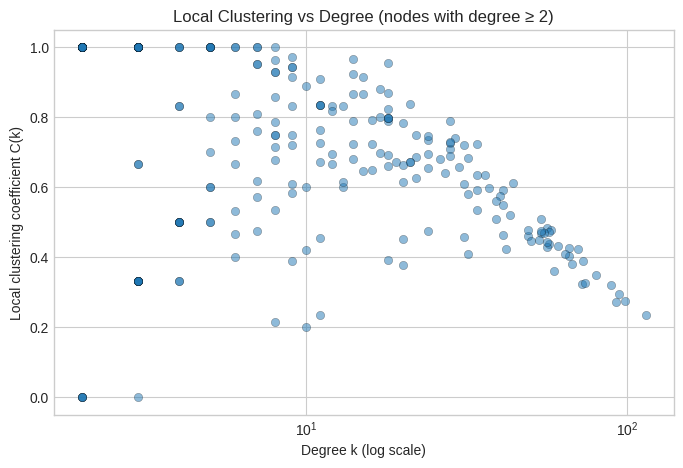


Highest-clustering stocks among nodes with degree >= 5:


,Stock,Sector,k,Clustering
0,BAJAJ-AUTO.NS,Automobile and Auto Components,5,1.0
1,BLS.NS,Consumer Services,5,1.0
2,CHOLAHLDNG.NS,Financial Services,7,1.0
3,COFORGE.NS,Information Technology,8,1.0
4,ENGINERSIN.NS,Construction,5,1.0


In [ ]:
avg_c_all  = nx.average_clustering(G)          # includes isolated nodes (C = 0)
avg_c_core = nx.average_clustering(G_core)     # excludes isolated nodes
transitivity = nx.transitivity(G)              # global clustering: 3 x triangles / connected triples
density = nx.density(G)
er_c = nx.average_clustering(G_er)

print(f"Average Clustering Coefficient (all nodes)          : {avg_c_all:.4f}")
print(f"Average Clustering Coefficient (non-isolated nodes) : {avg_c_core:.4f}")
print(f"Global clustering (transitivity)                    : {transitivity:.4f}")
print(f"Network density                                     : {density:.4f}")
print(f"Random graph (same n, m) average clustering         : {er_c:.4f}  "
      f"-> observed is ~{avg_c_all/max(er_c, 1e-12):.0f}x higher")

# Individual node clustering coefficients
clustering_per_node = nx.clustering(G)
centrality_df['Clustering'] = centrality_df['Stock'].map(clustering_per_node)

# Clustering coefficient versus degree
plt.figure(figsize=(8, 5))
cdf = centrality_df.assign(k=[G.degree(n) for n in centrality_df['Stock']])
cdf = cdf[cdf['k'] >= 2]
plt.scatter(cdf['k'], cdf['Clustering'], alpha=0.5, edgecolor='k', linewidth=0.3)
plt.xscale('log'); plt.xlabel('Degree k (log scale)'); plt.ylabel('Local clustering coefficient C(k)')
plt.title('Local Clustering vs Degree (nodes with degree ≥ 2)')
plt.show()
print("\nHighest-clustering stocks among nodes with degree >= 5:")
display(cdf[cdf['k'] >= 5].nlargest(5, 'Clustering')[['Stock', 'Sector', 'k', 'Clustering']].reset_index(drop=True))

### 7.1 Sector homophily
Do stocks of the same industry connect to each other more than chance would predict? We use the **Industry** field of the NSE constituent file and measure:

1. the fraction of edges whose two ends are in the same sector, versus a **random baseline** obtained by shuffling sector labels 2,000 times (z-score and permutation p-value);
2. the **attribute assortativity coefficient** of the sector label (0 = random mixing, 1 = perfect homophily);
3. the fraction of **triangles** whose three nodes are all in the same sector, versus the same shuffled baseline.

In [ ]:
nodes = list(G.nodes())
idx = {n: i for i, n in enumerate(nodes)}
labels = np.array([sector_map[n] for n in nodes])
n_unknown = int((labels == 'Unknown').sum())
print(f"Nodes with unknown sector: {n_unknown}")

# ---------- 1. Intra-sector edge ratio vs shuffled-label baseline ----------
edges_idx = np.array([(idx[u], idx[v]) for u, v in G.edges()])
obs_edge = (labels[edges_idx[:, 0]] == labels[edges_idx[:, 1]]).mean()
null_edge = np.array([(lp[edges_idx[:, 0]] == lp[edges_idx[:, 1]]).mean()
                      for lp in (np.random.permutation(labels) for _ in range(2000))])
z_edge = (obs_edge - null_edge.mean()) / null_edge.std()
p_edge = (np.sum(null_edge >= obs_edge) + 1) / (len(null_edge) + 1)
print(f"\nIntra-sector edge ratio: observed = {obs_edge:.2%} | random-label baseline = {null_edge.mean():.2%} "
      f"(± {null_edge.std():.2%}) | z = {z_edge:.1f} | p = {p_edge:.4f}")

# ---------- 2. Assortativity of the sector attribute ----------
assort = nx.attribute_assortativity_coefficient(G, 'sector')
print(f"Sector assortativity coefficient: {assort:.3f}")

# ---------- 3. Triangles inside a single sector ----------
tri = set()
for u, v in G.edges():
    for w in set(G[u]) & set(G[v]):
        tri.add(frozenset((u, v, w)))
tri_idx = np.array([[idx[n] for n in t] for t in tri])
def same3(lab):
    return ((lab[tri_idx[:, 0]] == lab[tri_idx[:, 1]]) & (lab[tri_idx[:, 1]] == lab[tri_idx[:, 2]])).mean()
obs_tri = same3(labels)
null_tri = np.array([same3(np.random.permutation(labels)) for _ in range(1000)])
print(f"Triangles: {len(tri):,} | all three nodes in the same sector: observed = {obs_tri:.2%} "
      f"vs random-label baseline = {null_tri.mean():.2%}")

if p_edge < 0.05 and assort > 0:
    print("\n=> Sector homophily is statistically significant: same-industry stocks are linked more often than chance.")
else:
    print("\n=> No significant sector homophily detected at this threshold.")

# ---------- Per-sector table ----------
rows = []
for s in pd.Series(labels).value_counts().index:
    m0 = labels[edges_idx[:, 0]] == s
    m1 = labels[edges_idx[:, 1]] == s
    members = [n for n in nodes if sector_map[n] == s]
    rows.append({'Sector': s, 'Stocks': len(members),
                 'Edges touching sector': int((m0 | m1).sum()),
                 'Share of those edges that stay inside': (m0 & m1).sum() / max((m0 | m1).sum(), 1),
                 'Avg clustering': np.mean([clustering_per_node[n] for n in members])})
sector_table = pd.DataFrame(rows).set_index('Sector')
print("\nPer-sector summary:")
display(sector_table.round(3))

Nodes with unknown sector: 0

Intra-sector edge ratio: observed = 37.67% | random-label baseline = 9.20% (± 1.25%) | z = 22.7 | p = 0.0005
Sector assortativity coefficient: 0.225
Triangles: 14,206 | all three nodes in the same sector: observed = 16.84% vs random-label baseline = 1.24%

=> Sector homophily is statistically significant: same-industry stocks are linked more often than chance.

Per-sector summary:


,Stocks,Edges touching sector,Share of those edges that stay inside,Avg clustering
Sector,,,,
Financial Services,98,1347,0.366,0.462
Capital Goods,69,388,0.209,0.264
Healthcare,44,1,1.000,0.000
Automobile and Auto Components,40,281,0.206,0.384
Fast Moving Consumer Goods,28,18,0.278,0.057
Chemicals,26,57,0.088,0.164
Information Technology,24,62,0.984,0.505
Consumer Services,23,108,0.065,0.286
Metals & Mining,18,93,0.419,0.528


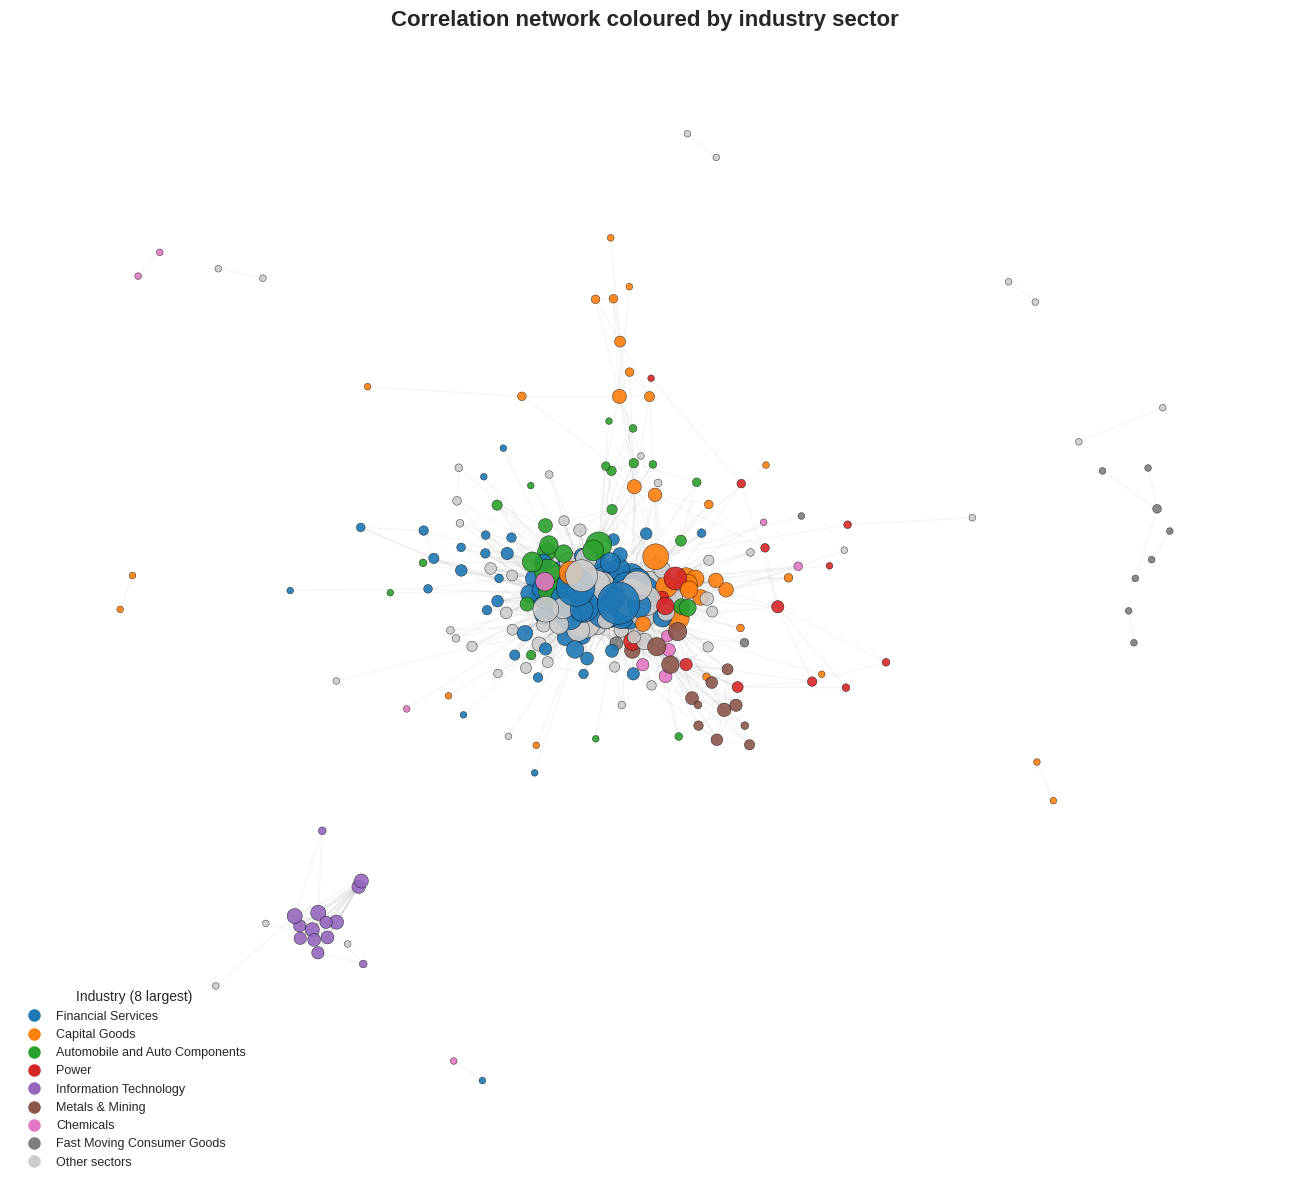

In [ ]:
# ---------- Visualisation: nodes coloured by sector ----------
top_sectors = pd.Series([sector_map[n] for n in G_core.nodes()]).value_counts().index[:8].tolist()
palette = dict(zip(top_sectors, plt.cm.tab10.colors))
node_colors = [palette.get(sector_map[n], (0.8, 0.8, 0.8)) for n in G_core.nodes()]

plt.figure(figsize=(13, 12))
nx.draw_networkx_edges(G_core, pos, alpha=0.08, edge_color='gray')
nx.draw_networkx_nodes(G_core, pos, node_color=node_colors,
                       node_size=[degrees_dict[n] * 8 + 15 for n in G_core.nodes()],
                       alpha=0.9, edgecolors='black', linewidths=0.3)
handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=c, markersize=10, label=s)
           for s, c in palette.items()]
handles.append(plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=(0.8, 0.8, 0.8), markersize=10, label='Other sectors'))
plt.legend(handles=handles, loc='lower left', title='Industry (8 largest)', fontsize=9)
plt.title('Correlation network coloured by industry sector', fontsize=16, fontweight='bold')
plt.axis('off'); plt.tight_layout(); plt.show()

### Interpretation of clustering and sector homophily
* **High clustering.** The average clustering coefficient of 0.31 (at $r=0.5$, all nodes) is roughly **16 times** that of a random graph with the same number of nodes and edges (density ≈ 0.019). So the network is highly transitive: if stock A and stock B both correlate with C, they very likely correlate with each other. This happens because of a shared driver (the market factor, a sector, a business group), which creates groups (cliques) of mutually correlated stocks rather than independent pairwise links.
* **Clustering vs degree.** In correlation networks, low-degree nodes typically sit inside tight groups (high $C$), whereas hubs link several groups together and therefore have lower $C$. The scatter plot above shows whether that pattern holds here.
* **Sector homophily.** Read the three tests printed above together: (i) the observed intra-sector edge ratio compared with the shuffled baseline (z-score, p-value), (ii) the sector assortativity coefficient, and (iii) the share of triangles lying within one sector. Values clearly above the baseline mean that triangles form naturally within industries (e.g. banks with banks, IT with IT, power/infra together) on top of the market-wide co-movement; the per-sector table shows which industries are the most self-contained. Sectors with a low "share that stays inside" are those whose stocks are linked mainly to *other* sectors (they act as cross-sector connectors, which is also what raises betweenness).
* **Caveat.** The `Industry` field is a coarse classification, so some "cross-sector" edges reflect real business links (e.g. cement ↔ infrastructure) or group effects that the label cannot capture.

## 8. Analysis D: Threshold sensitivity (the "what-if" study)
We rebuild the network for correlation thresholds $r=0.30,0.35,\dots,0.85$ and track: number of edges, density, number of isolated nodes, size of the **giant (largest connected) component**, **average shortest-path length** (computed on the giant component, since it is undefined for a disconnected graph) and average clustering.

*Caution:* when the giant component shrinks to a handful of nodes, its average path length says nothing about the market, so such points are flagged (giant component < 20 nodes) and shaded in the plot.

In [ ]:
thresholds = np.round(np.arange(0.30, 0.851, 0.05), 2)
corr_vals = corr_matrix.values
N_nodes = corr_vals.shape[0]
MIN_GIANT = 20                         # below this size the path length is not meaningful

def top10_hubs(A):
    """Indices of the 10 highest-degree nodes (None if fewer than 10 nodes have any edge)."""
    deg = A.sum(axis=1)
    if (deg > 0).sum() < 10:
        return None
    return set(np.argsort(-deg, kind='stable')[:10])

A_ref = (corr_vals > THRESHOLD).astype(int); np.fill_diagonal(A_ref, 0)
ref_hubs = top10_hubs(A_ref)           # top-10 hubs at the reference threshold (r = 0.5)

results = []
for r in thresholds:
    A = (corr_vals > r).astype(int)
    np.fill_diagonal(A, 0)
    G_r = nx.from_numpy_array(A)

    comps_r = sorted(nx.connected_components(G_r), key=len, reverse=True)
    giant = comps_r[0]
    G_giant = G_r.subgraph(giant)
    avg_path = nx.average_shortest_path_length(G_giant) if len(giant) > 1 else np.nan

    hubs_r = top10_hubs(A)
    hub_overlap = (len(hubs_r & ref_hubs) / 10) if (hubs_r is not None and ref_hubs is not None) else np.nan

    results.append({
        'Threshold': r,
        'Edges': G_r.number_of_edges(),
        'Density': nx.density(G_r),
        'Isolated_nodes': sum(1 for _ in nx.isolates(G_r)),
        'Components': len(comps_r),
        'Giant_Component_Size': len(giant),
        'Giant_Fraction': len(giant) / N_nodes,
        'Avg_Path_Length': avg_path,
        'Avg_Clustering': nx.average_clustering(G_r),
        'Path_Length_Reliable': len(giant) >= MIN_GIANT,
        'Top10_Hub_Overlap_vs_r0.5': hub_overlap,   # robustness of the hub list to the threshold
    })

sensitivity_df = pd.DataFrame(results)
display(sensitivity_df.round(4))

,Threshold,Edges,Density,Isolated_nodes,Components,Giant_Component_Size,Giant_Fraction,Avg_Path_Length,Avg_Clustering,Path_Length_Reliable,Top10_Hub_Overlap_vs_r0.5
0,0.30,36729,0.3053,7,8,484,0.9857,1.7790,0.7253,True,0.6
1,0.35,21895,0.1820,29,31,460,0.9369,2.0142,0.6448,True,0.8
2,0.40,11482,0.0954,68,72,417,0.8493,2.3774,0.5539,True,0.8
3,0.45,5328,0.0443,141,148,324,0.6599,2.4038,0.4225,True,1.0
4,0.50,2291,0.0190,212,226,238,0.4847,2.5439,0.3120,True,1.0
5,0.55,925,0.0077,289,301,159,0.3238,2.8383,0.1973,True,0.8
6,0.60,378,0.0031,341,359,106,0.2159,3.2424,0.1446,True,0.7
7,0.65,164,0.0014,382,403,49,0.0998,4.1054,0.0941,True,0.2
8,0.70,83,0.0007,423,440,9,0.0183,1.6944,0.0695,False,0.1
9,0.75,34,0.0003,448,464,5,0.0102,1.2000,0.0258,False,0.0


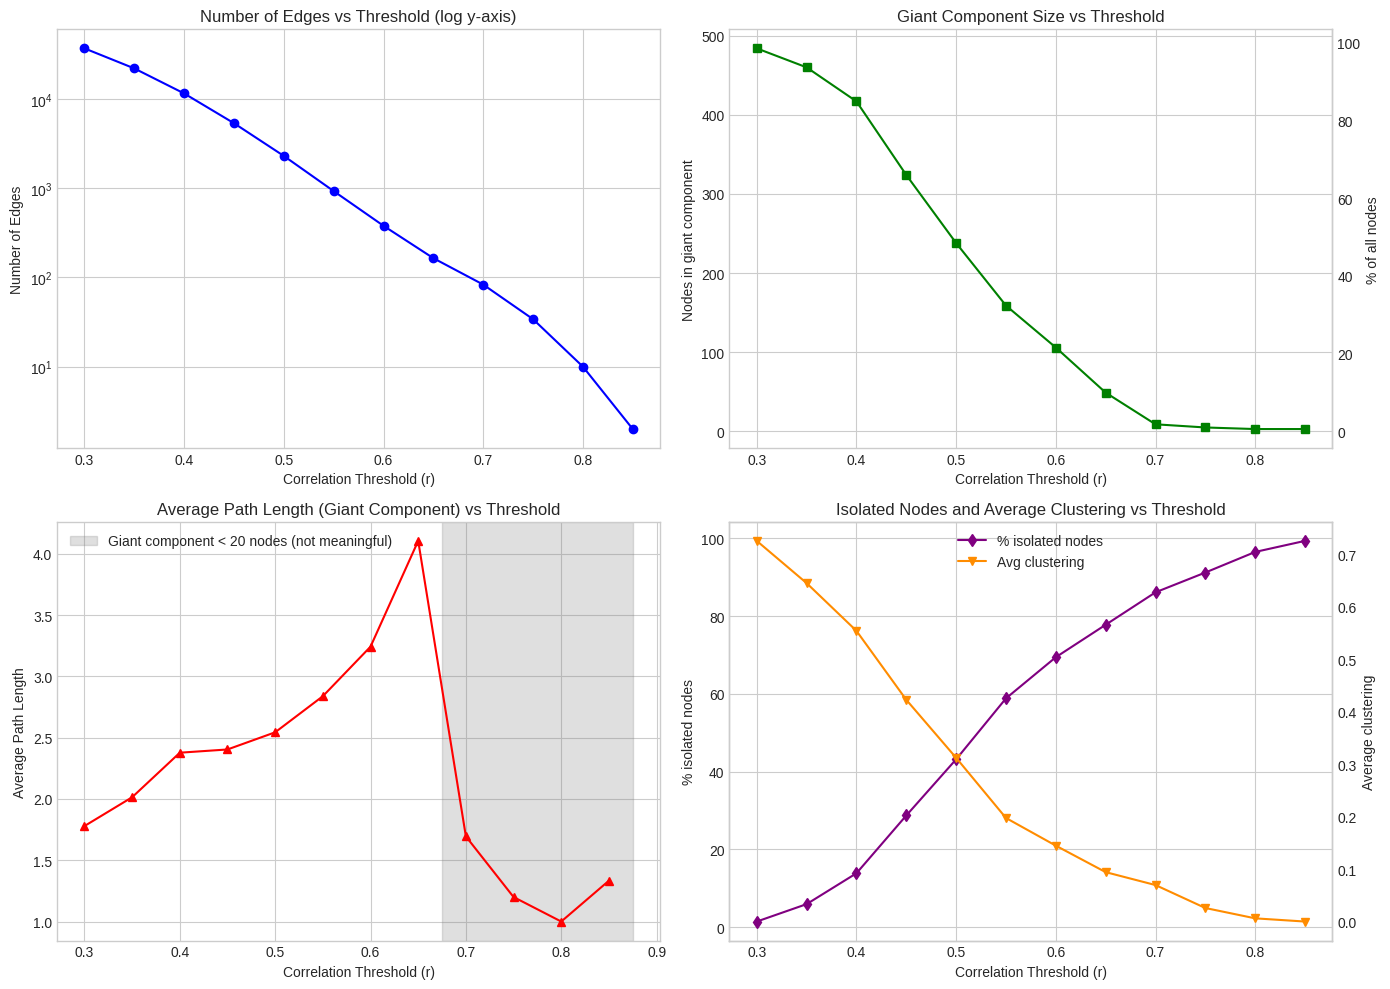

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
t = sensitivity_df['Threshold']
unreliable = sensitivity_df.loc[~sensitivity_df['Path_Length_Reliable'], 'Threshold']

# 1. Edges (log scale because the count falls by orders of magnitude)
axes[0, 0].plot(t, sensitivity_df['Edges'].replace(0, np.nan), marker='o', color='b')   # 0 edges cannot be shown on a log axis
axes[0, 0].set_yscale('log'); axes[0, 0].set_title('Number of Edges vs Threshold (log y-axis)')
axes[0, 0].set_ylabel('Number of Edges')

# 2. Giant component fraction
axes[0, 1].plot(t, sensitivity_df['Giant_Component_Size'], marker='s', color='g')
axes[0, 1].set_title('Giant Component Size vs Threshold')
axes[0, 1].set_ylabel('Nodes in giant component')
sec = axes[0, 1].secondary_yaxis('right', functions=(lambda y: y / N_nodes * 100, lambda y: y * N_nodes / 100))
sec.set_ylabel('% of all nodes')

# 3. Average path length (giant component)
axes[1, 0].plot(t, sensitivity_df['Avg_Path_Length'], marker='^', color='r')
axes[1, 0].set_title('Average Path Length (Giant Component) vs Threshold')
axes[1, 0].set_ylabel('Average Path Length')
if len(unreliable):
    axes[1, 0].axvspan(unreliable.min() - 0.025, t.max() + 0.025, color='gray', alpha=0.25,
                       label=f'Giant component < {MIN_GIANT} nodes (not meaningful)')
    axes[1, 0].legend()

# 4. Isolated nodes and clustering
axes[1, 1].plot(t, sensitivity_df['Isolated_nodes'] / N_nodes * 100, marker='d', color='purple', label='% isolated nodes')
axes[1, 1].set_ylabel('% isolated nodes')
ax2 = axes[1, 1].twinx()
ax2.plot(t, sensitivity_df['Avg_Clustering'], marker='v', color='darkorange', label='Avg clustering')
ax2.set_ylabel('Average clustering'); ax2.grid(False)
axes[1, 1].set_title('Isolated Nodes and Average Clustering vs Threshold')
h1, l1 = axes[1, 1].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
axes[1, 1].legend(h1 + h2, l1 + l2, loc='upper center')

for ax in axes.ravel():
    ax.set_xlabel('Correlation Threshold (r)'); ax.grid(True)
plt.tight_layout(); plt.show()

### Interpretation of the threshold sensitivity
Results from the cached run (re-check against the table above if you re-download data):

| r | Edges | Giant component (nodes) | Avg path length |
|---|---|---|---|
| 0.30 | 36,797 | 482 (98%) | 1.77 |
| 0.50 | 2,283 | 233 (48%) | 2.52 |
| 0.60 | 369 | 105 | 3.32 |
| 0.65 | 161 | 48 | 5.37 |
| 0.70 | 83 | 9 | 1.69 (not meaningful) |
| 0.80 | 10 | 3 | 1.00 (not meaningful) |

* **Edges fall quickly.** Each 0.05 increase in $r$ removes roughly 40–70% of the remaining edges, from tens of thousands at $r=0.3$ to a handful at $r=0.8$. The "network" is therefore very sensitive to how strictly a connection is defined.
* **Fragmentation (percolation-like collapse).** The giant component holds ~98% of the stocks at $r=0.3$, about half at $r=0.5$, and then collapses between $r=0.6$ and $r=0.7$ (105 → 48 → 9 nodes). Beyond $r≈0.65$ the market no longer forms one connected structure, only a few small clusters of very tightly co-moving stocks.
* **Path length peaks near the breaking point.** At low $r$ the graph is dense with short paths (≈ 1.8 hops). As edges are removed, paths get longer (up to ≈ 5.4 at $r=0.65$) because the giant component thins into chain-like structures just before it disintegrates. At higher $r$ the path length drops again, but only because the "giant component" is now a tiny cluster: this is an artefact (shaded in the plot), not "a more compact market".
* **Implication for our choice of $r=0.5$.** At $r=0.5$ roughly half of the nodes are outside the giant component, so the conclusions of Sections 5–7 describe the strongly co-moving core of the market, not all stocks. The qualitative picture (hubs, high clustering) should be checked at another threshold such as 0.4 to confirm robustness.
* **Robust vs fragile.** Connectivity is robust at low thresholds (the common market factor links nearly everybody) and fragile at high thresholds, where only sector- or group-specific clusters survive.

## 9. Discussion and Conclusion
**Summary of findings** (Nifty 500, 1 year of daily log-returns, $r=0.5$ unless stated):

1. **Degree distribution.** Strongly right-skewed with a few big hubs (max degree more than 10 times the mean) and much heavier than a random graph of the same size; a clean power law cannot be claimed from a ~490-node network, but the market is clearly *not* random-like.
2. **Centrality.** UCO Bank, Jio Financial, Shriram Finance, NBCC, Ambuja Cements, Inox Wind and CDSL dominate the three leaderboards. The leaders are mid-cap, pro-cyclical, domestic-oriented and often high-beta stocks, not the index heavyweights (Reliance, TCS, HDFC Bank), showing that *centrality in a correlation network measures co-movement, not size*.
3. **Clustering and sectors.** Average clustering (≈ 0.31) is about 16 times the random-graph level: correlated stocks form tight groups. The permutation tests in Section 7.1 quantify how much of this is explained by industry sector; group-level effects (e.g. the Adani cement companies) also matter.
4. **Threshold sensitivity.** The structure is strongly threshold dependent: the giant component collapses between $r=0.6$ and $0.7$, so any quantitative result must be reported with the threshold used.

**Limitations.** (i) A single 1-year window is dominated by whatever market regime occurred during it; results may change over other periods. (ii) Pearson correlation on daily returns captures linear co-movement and is affected by the common market factor; filtering methods (e.g. minimum spanning trees, random-matrix cleaning), which the assignment did not require, could reveal finer structure. (iii) Correlation is not causation, so "central" does not mean "influential". (iv) Sector labels are coarse. (v) The power-law check is a simple regression-based heuristic.

**Possible extensions.** Rolling-window networks to study how hubs change in crises, weighted networks, community detection compared with the sector labels, and a hub-removal (robustness) experiment.

## 10. References
[1] Tse, C. K., Liu, J., & Lau, F. C. M. (2010). A network perspective of the stock market. *Journal of Empirical Finance*, 17(4), 659–667.

[2] Moghadam, H. E., et al. (2019). Complex networks analysis in Iran stock market: The application of centrality. *Physica A: Statistical Mechanics and its Applications*, 531, 121800.